### Exploratory data analysis

This notebook checks the training and prediction data before modeling. The main goals are to find incorrect or missing values, understand what drives `posted_rate`, and confirm that a future-period validation split is appropriate.

In [22]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 30)
plt.style.use("seaborn-v0_8-whitegrid")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"

train = pd.read_csv(DATA / "train-test.csv", parse_dates=["date"])
validation = pd.read_csv(DATA / "validation.csv", parse_dates=["date"])
december = pd.read_csv(DATA / "december-chart-inputs.csv", parse_dates=["date"])

### Coverage

The training file contains known rates from January through October. The validation file contains November and December loads without rates, so model quality must be measured by holding out the latest part of the training data. The December chart file is a separate fixed-route example, not a duplicate of the validation set.

In [23]:
pd.DataFrame({
    "rows": [len(train), len(validation), len(december)],
    "columns": [train.shape[1], validation.shape[1], december.shape[1]],
    "date_min": [train.date.min(), validation.date.min(), december.date.min()],
    "date_max": [train.date.max(), validation.date.max(), december.date.max()],
}, index=["train", "validation", "december"])

,rows,columns,date_min,date_max
train,48000,14,2025-01-01,2025-10-31
validation,12000,13,2025-11-01,2025-12-31
december,31,7,2025-12-01,2025-12-31


### Schema

Column names and data types are checked before analysis. `posted_rate` should appear only in the labeled training file; the remaining model inputs should match between training and validation.

In [24]:
schema = pd.DataFrame({
    "train_dtype": train.dtypes.astype(str),
    "validation_dtype": validation.dtypes.astype(str),
})
schema

,train_dtype,validation_dtype
date,datetime64[ns],datetime64[ns]
delivery,object,object
delivery_lat,float64,float64
delivery_lon,float64,float64
distance,float64,float64
equipment,object,object
load_id,object,object
market_index,float64,float64
pickup,object,object
pickup_lat,float64,float64


In [25]:
train_features = set(train.columns) - {"posted_rate"}
pd.Series({
    "validation_missing": sorted(train_features - set(validation.columns)),
    "validation_extra": sorted(set(validation.columns) - train_features),
    "december_missing": sorted((train_features - {"load_id"}) - set(december.columns)),
}, name="columns").to_frame()

,columns
validation_missing,[]
validation_extra,[]
december_missing,"[delivery_lat, delivery_lon, market_index, pic..."


### Missing values

The table reports both the number of missing rows and the percentage of each dataset. For example, 1% means one row out of every 100 is missing that value. This check shows whether a simple median replacement is enough or whether a column has a larger quality problem.

In [26]:
missing = pd.concat({
    "train_count": train.isna().sum(),
    "train_pct": train.isna().mean().mul(100),
    "validation_count": validation.isna().sum(),
    "validation_pct": validation.isna().mean().mul(100),
}, axis=1).fillna(0)
missing.loc[missing.max(axis=1).gt(0)].round(2)

,train_count,train_pct,validation_count,validation_pct
weight,300,0.62,165.0,1.38
market_index,374,0.78,249.0,2.08


### Weight quality

A load cannot have a negative physical weight. We compare the absolute values of negative weights with valid weights to check whether the issue is only an incorrect minus sign. If the distributions are similar, correcting the sign is safer than deleting the rows.

In [27]:
pd.DataFrame({
    "train": {
        "missing": train.weight.isna().sum(),
        "zero": train.weight.eq(0).sum(),
        "negative": train.weight.lt(0).sum(),
    },
    "validation": {
        "missing": validation.weight.isna().sum(),
        "zero": validation.weight.eq(0).sum(),
        "negative": validation.weight.lt(0).sum(),
    },
})

,train,validation
missing,300,165
zero,0,0
negative,292,145


In [28]:
pd.DataFrame({
    "valid_train": train.loc[train.weight > 0, "weight"].describe(),
    "negative_train_absolute": train.loc[train.weight < 0, "weight"].abs().describe(),
    "valid_validation": validation.loc[validation.weight > 0, "weight"].describe(),
    "negative_validation_absolute": validation.loc[validation.weight < 0, "weight"].abs().describe(),
}).round(2)

,valid_train,negative_train_absolute,valid_validation,negative_validation_absolute
count,47408.00,292.00,11690.00,145.00
mean,31415.36,31724.20,31278.01,31681.82
std,7994.90,8262.54,7986.84,8094.23
min,5000.00,5000.00,5000.00,8229.00
25%,25922.00,25928.50,25746.50,26289.00
50%,31493.50,31821.50,31323.50,32517.00
75%,37063.00,37284.25,36922.00,37679.00
max,47500.00,47500.00,47500.00,47500.00


In [29]:
train.loc[
    train.weight < 0,
    ["load_id", "equipment", "distance", "weight", "posted_rate"],
].head(10)

,load_id,equipment,distance,weight,posted_rate
68,TR-000069,Reefer,1334.2,-36559.0,2831.27
204,TR-000205,Dry Van,496.2,-26670.0,1046.92
206,TR-000207,Reefer,411.3,-20003.0,959.15
225,TR-000226,Reefer,1317.4,-23981.0,2836.00
376,TR-000377,Dry Van,1331.1,-41397.0,2522.54
446,TR-000447,Reefer,2438.3,-37215.0,4841.57
495,TR-000496,Dry Van,715.9,-31214.0,1473.78
641,TR-000642,Dry Van,582.4,-41023.0,1264.33
806,TR-000807,Dry Van,676.1,-28320.0,1307.76
1093,TR-001094,Dry Van,1058.5,-25153.0,1907.83


### Missingness by month

Missing and negative values are counted by month. A problem concentrated in one month could indicate a broken data feed; a small amount spread across the year is more consistent with occasional entry errors.

In [30]:
def quality_by_month(frame):
    return (
        frame.assign(month=frame.date.dt.to_period("M"))
        .groupby("month")
        .agg(
            rows=("load_id", "size"),
            missing_weight_pct=("weight", lambda values: values.isna().mean() * 100),
            negative_weight_pct=("weight", lambda values: values.lt(0).mean() * 100),
            missing_market_pct=("market_index", lambda values: values.isna().mean() * 100),
        )
        .round(2)
    )

pd.concat({
    "train": quality_by_month(train),
    "validation": quality_by_month(validation),
})

rows  missing_weight_pct  negative_weight_pct  \
           month                                                    
train      2025-01  4918                0.69                 0.63   
           2025-02  4337                0.76                 0.69   
           2025-03  5036                0.71                 0.79   
           2025-04  4819                0.42                 0.52   
           2025-05  4913                0.45                 0.81   
           2025-06  4783                0.67                 0.63   
           2025-07  4912                0.59                 0.45   
           2025-08  4759                0.61                 0.32   
           2025-09  4670                0.71                 0.56   
           2025-10  4853                0.66                 0.68   
validation 2025-11  5836                1.41                 1.30   
           2025-12  6164                1.35                 1.12   

                    missing_market_pct  
           month                        
train      2025-01                0.73  
           2025-02                0.83  
           2025-03                0.87  
           2025-04                0.64  
           2025-05                0.88  
           2025-06                0.88  
           2025-07                0.73  
           2025-08                0.69  
           2025-09                0.66  
           2025-10                0.87  
validation 2025-11                1.97  
           2025-12                2.17

### Integrity

These checks look for duplicate rows or IDs, non-positive distance or target values, and coordinates outside valid latitude and longitude ranges. Any failure here would require correction before training because it could create misleading features or duplicate evidence.

In [31]:
pd.Series({
    "duplicate_rows": train.duplicated().sum(),
    "duplicate_load_ids": train.load_id.duplicated().sum(),
    "missing_load_ids": train.load_id.isna().sum(),
    "non_positive_distance": train.distance.le(0).sum(),
    "non_positive_weight": train.weight.dropna().le(0).sum(),
    "non_positive_target": train.posted_rate.le(0).sum(),
    "invalid_coordinates": (
        ~train.pickup_lat.between(-90, 90)
        | ~train.delivery_lat.between(-90, 90)
        | ~train.pickup_lon.between(-180, 180)
        | ~train.delivery_lon.between(-180, 180)
    ).sum(),
}, name="count").to_frame()

,count
duplicate_rows,0
duplicate_load_ids,0
missing_load_ids,0
non_positive_distance,0
non_positive_weight,292
non_positive_target,0
invalid_coordinates,0


### Target

`posted_rate` is the value the final model must predict. Rate per mile is calculated here only to compare short and long trips on the same scale. It is never used as an input feature because it contains the target.

In [32]:
# Diagnostic only: rate_per_mile uses the target and cannot be a model feature.
train["rate_per_mile"] = train.posted_rate / train.distance
train[["posted_rate", "rate_per_mile", "distance", "weight", "market_index", "quote_signal"]].describe(
    percentiles=[0.01, 0.05, 0.50, 0.95, 0.99]
).T

,count,mean,std,min,1%,5%,50%,95%,99%,max
posted_rate,48000.0,2373.980682,1486.493245,57.220000,327.168800,599.738500,2030.760000,4953.766500,5972.834000,25533.000000
rate_per_mile,48000.0,2.215347,0.583887,0.333709,1.673521,1.807533,2.145348,2.735925,3.176940,14.125294
distance,48000.0,1135.856654,728.564416,70.000000,121.899000,236.100000,953.300000,2562.300000,3029.304000,3439.800000
weight,47700.0,31028.844004,9391.440620,-47500.000000,9801.960000,17490.950000,31436.500000,44934.200000,47500.000000,47500.000000
market_index,47626.0,1.083387,0.168091,0.676390,0.782887,0.836265,1.055800,1.365957,1.407185,1.467780
quote_signal,48000.0,2.062468,0.291391,0.692280,1.304657,1.606055,2.055750,2.550773,2.883951,3.610350


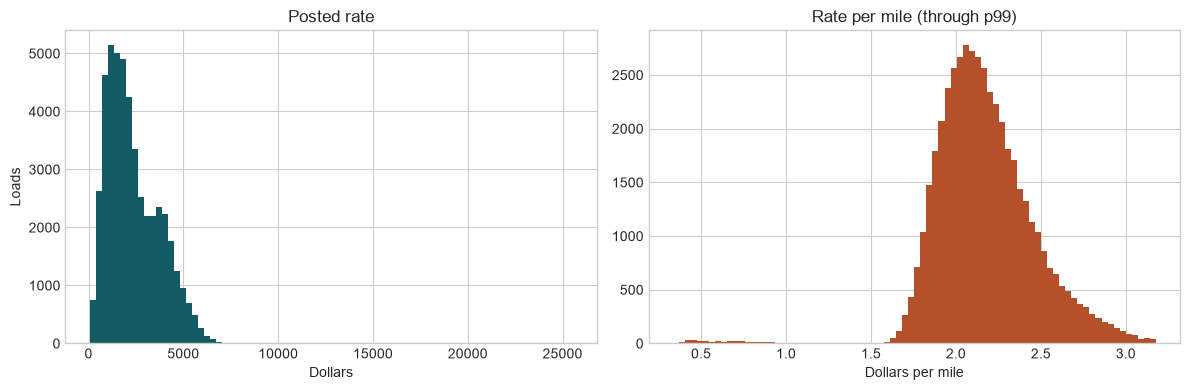

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(train.posted_rate, bins=80, color="#145A67")
axes[0].set(title="Posted rate", xlabel="Dollars", ylabel="Loads")
# Filter the display at p99; clipping would create an artificial spike.
rate_per_mile_p99 = train.rate_per_mile.quantile(0.99)
axes[1].hist(
    train.loc[train.rate_per_mile <= rate_per_mile_p99, "rate_per_mile"],
    bins=80,
    color="#B4512A",
)
axes[1].set(title="Rate per mile (through p99)", xlabel="Dollars per mile")
plt.tight_layout()

### Target outliers

The highest rates and rates per mile are inspected for patterns such as one month, lane, or equipment type. An unusual rate is removed only when there is evidence that it is incorrect. A valid but rare price must remain because the final data may contain the same type of load.

In [34]:
train.nlargest(10, "posted_rate")[
    ["load_id", "pickup", "delivery", "distance", "equipment", "weight", "posted_rate", "rate_per_mile"]
]

,load_id,pickup,delivery,distance,equipment,weight,posted_rate,rate_per_mile
12184,TR-012185,Bakersfield,Hartford,2829.8,Dry Van,33153.0,25533.00,9.022899
37764,TR-037765,Phoenix,Syracuse,2810.9,Dry Van,33674.0,24294.98,8.643132
1466,TR-001467,Los Angeles,Syracuse,2786.0,Reefer,30322.0,24140.21,8.664828
17371,TR-017372,Reno,Philadelphia,2777.6,Reefer,33158.0,23662.71,8.519121
26235,TR-026236,Charleston,Phoenix,2552.5,Dry Van,25665.0,23580.42,9.238167
28219,TR-028220,Tucson,Raleigh,2423.3,Dry Van,30972.0,22755.66,9.390360
3353,TR-003354,Phoenix,Charleston,2527.9,Reefer,36840.0,22534.65,8.914376
40171,TR-040172,Montgomery,Fresno,2283.4,Dry Van,32447.0,20361.89,8.917356
40096,TR-040097,Baltimore,Oklahoma City,1760.3,Reefer,29521.0,20132.37,11.436897
47298,TR-047299,Boston,Bakersfield,2979.1,Reefer,30585.0,19110.30,6.414790


In [35]:
train.nlargest(10, "rate_per_mile")[
    ["load_id", "pickup", "delivery", "distance", "equipment", "weight", "posted_rate", "rate_per_mile"]
]

,load_id,pickup,delivery,distance,equipment,weight,posted_rate,rate_per_mile
22254,TR-022255,Greensboro,Cincinnati,314.7,Reefer,-36485.0,4445.23,14.125294
36609,TR-036610,Chattanooga,Atlanta,98.4,Reefer,22226.0,1386.42,14.089634
870,TR-000871,Tulsa,Baton Rouge,305.6,Reefer,26447.0,4069.24,13.315576
17070,TR-017071,Toledo,Dayton,201.5,Flatbed,38714.0,2609.34,12.949578
27969,TR-027970,Buffalo,Boston,589.9,Reefer,24951.0,7597.52,12.879335
23369,TR-023370,Amarillo,Lubbock,412.4,Flatbed,35494.0,5308.96,12.873327
28012,TR-028013,Montgomery,Houston,604.3,Reefer,39690.0,7773.37,12.863429
45483,TR-045484,Greensboro,Columbia,153.8,Dry Van,34198.0,1971.21,12.816710
1415,TR-001416,Montgomery,Birmingham,198.2,Reefer,25383.0,2509.96,12.663774
21968,TR-021969,Jacksonville,Columbia,254.5,Dry Van,32993.0,3220.66,12.654853


### Numeric relationships

Correlation shows whether two numeric columns move together in a straight-line pattern. Values close to 1 or -1 are strong; values close to 0 are weak. CatBoost can still learn curved relationships and interactions, so a low correlation does not mean a feature is useless.

In [36]:
numeric = ["posted_rate", "rate_per_mile", "distance", "weight", "market_index", "quote_signal"]
train[numeric].corr().round(3)

,posted_rate,rate_per_mile,distance,weight,market_index,quote_signal
posted_rate,1.000,0.003,0.909,0.035,0.034,-0.040
rate_per_mile,0.003,1.000,-0.335,0.075,0.083,0.049
distance,0.909,-0.335,1.000,0.003,-0.002,-0.057
weight,0.035,0.075,0.003,1.000,-0.001,0.008
market_index,0.034,0.083,-0.002,-0.001,1.000,-0.068
quote_signal,-0.040,0.049,-0.057,0.008,-0.068,1.000


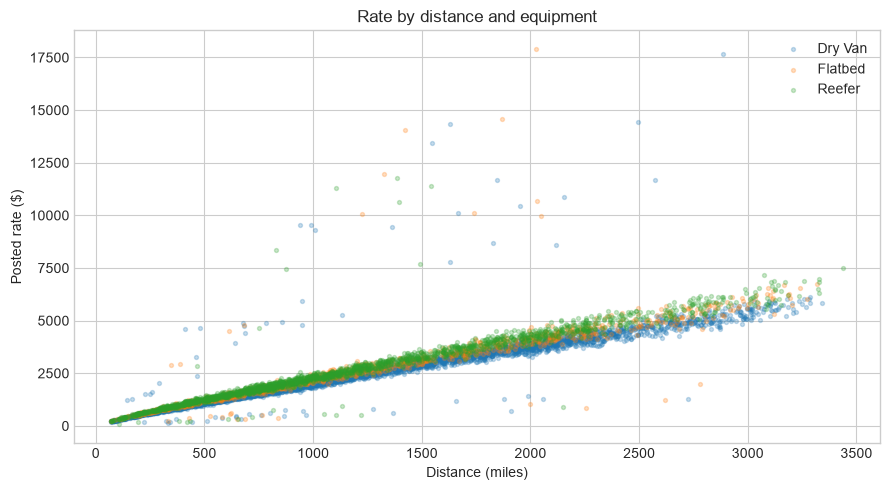

In [37]:
sample = train.sample(min(8_000, len(train)), random_state=42)
fig, ax = plt.subplots(figsize=(9, 5))
for equipment, group in sample.groupby("equipment"):
    ax.scatter(group.distance, group.posted_rate, s=8, alpha=0.25, label=equipment)
ax.set(title="Rate by distance and equipment", xlabel="Distance (miles)", ylabel="Posted rate ($)")
ax.legend()
plt.tight_layout()

### Equipment and distance

Median is used because a few extreme rates can distort the average. The tables show whether equipment changes price and whether rate per mile falls as trip length increases. These patterns help decide which features and interactions the model needs.

In [38]:
train.groupby("equipment", observed=True).agg(
    loads=("load_id", "size"),
    median_distance=("distance", "median"),
    median_rate=("posted_rate", "median"),
    median_rate_per_mile=("rate_per_mile", "median"),
).round(2)

,loads,median_distance,median_rate,median_rate_per_mile
equipment,,,,
Dry Van,27202,957.55,1953.04,2.05
Flatbed,8753,940.00,2076.81,2.22
Reefer,12045,950.20,2196.67,2.31


In [39]:
distance_bins = [0, 250, 500, 1_000, 2_000, np.inf]
distance_labels = ["0-250", "251-500", "501-1000", "1001-2000", "2000+"]
train["distance_band"] = pd.cut(train.distance, bins=distance_bins, labels=distance_labels)
train.groupby("distance_band", observed=True).agg(
    loads=("load_id", "size"),
    median_rate=("posted_rate", "median"),
    median_rate_per_mile=("rate_per_mile", "median"),
).round(2)

,loads,median_rate,median_rate_per_mile
distance_band,,,
0-250,2713,506.09,2.75
251-500,7577,924.07,2.42
501-1000,15055,1632.28,2.20
1001-2000,15108,2872.25,2.05
2000+,7547,4531.93,1.91


### Time

Daily load counts reveal missing or unusually quiet dates. Daily and monthly median rate per mile show changes in the market through the year. This also explains why a random train-test split would be misleading: future prices are not drawn from exactly the same period as earlier prices.

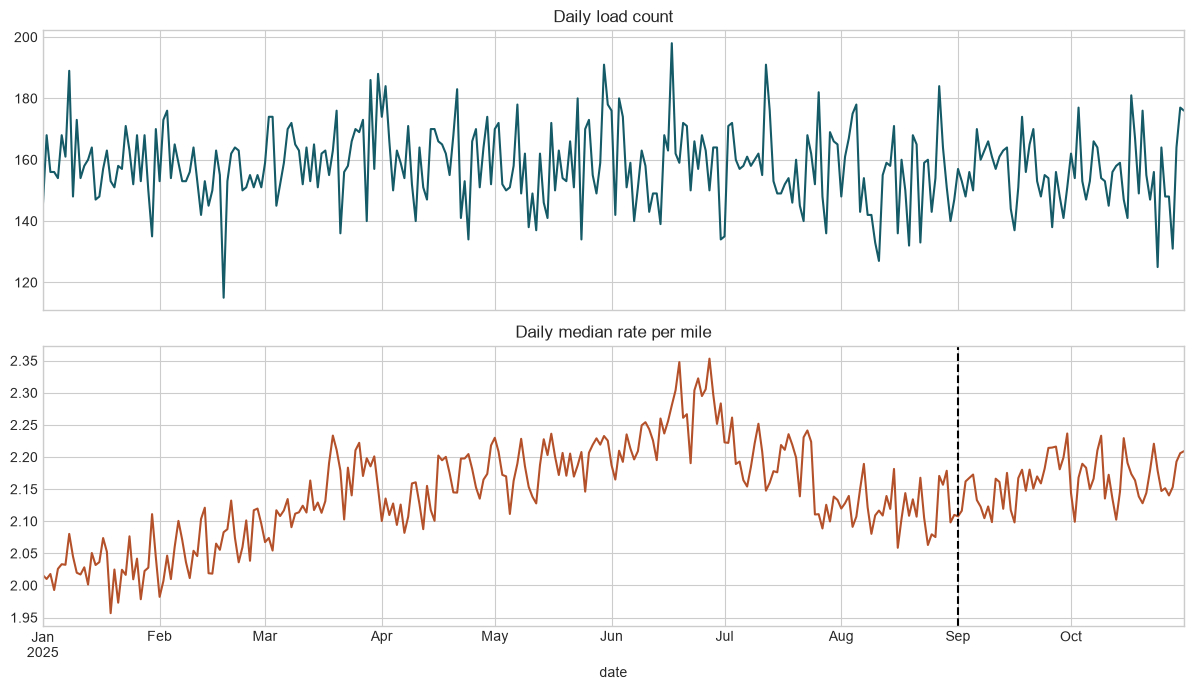

In [40]:
daily = train.groupby("date").agg(
    loads=("load_id", "size"),
    median_rate_per_mile=("rate_per_mile", "median"),
)
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
daily.loads.plot(ax=axes[0], color="#145A67", title="Daily load count")
daily.median_rate_per_mile.plot(ax=axes[1], color="#B4512A", title="Daily median rate per mile")
axes[1].axvline(pd.Timestamp("2025-09-01"), color="black", linestyle="--")
plt.tight_layout()

In [41]:
train.groupby(train.date.dt.to_period("M")).agg(
    loads=("load_id", "size"),
    median_rate=("posted_rate", "median"),
    median_rate_per_mile=("rate_per_mile", "median"),
    median_market_index=("market_index", "median"),
).round(3)

,loads,median_rate,median_rate_per_mile,median_market_index
date,,,,
2025-01,4918,1915.200,2.029,0.933
2025-02,4337,1994.250,2.061,0.993
2025-03,5036,2022.920,2.139,1.065
2025-04,4819,2044.240,2.147,1.207
2025-05,4913,2065.510,2.190,1.304
2025-06,4783,2120.220,2.248,1.275
2025-07,4912,2059.145,2.187,1.212
2025-08,4759,2015.730,2.121,0.982
2025-09,4670,2057.130,2.160,0.888


### Categorical coverage

The validation file may contain categories that did not appear in training. Equipment, pickup, and delivery coverage are checked separately so the model can be chosen and tested with unseen values in mind.

In [42]:
coverage_rows = []
for column in ["pickup", "delivery", "equipment"]:
    training_values = set(train[column].dropna())
    unseen_values = set(validation[column].dropna()) - training_values
    coverage_rows.append({
        "feature": column,
        "training_unique": train[column].nunique(),
        "validation_unique": validation[column].nunique(),
        "unseen_values": len(unseen_values),
        "validation_rows_unseen": validation[column].isin(unseen_values).sum(),
    })

pd.DataFrame(coverage_rows).set_index("feature")

,training_unique,validation_unique,unseen_values,validation_rows_unseen
feature,,,,
pickup,64,72,8,725
delivery,64,72,8,722
equipment,3,3,0,0


### Lane coverage

A lane is the pickup and delivery city pair. This section counts known lanes, new validation lanes, and the number of training examples available per lane. New lanes require the model to rely on distance, coordinates, pickup, delivery, and equipment instead of memorizing a route average.

In [43]:
train_lanes = set(zip(train.pickup, train.delivery))
validation_lanes = set(zip(validation.pickup, validation.delivery))
lane_counts = train.groupby(["pickup", "delivery"], observed=True).size()

pd.Series({
    "training_lanes": len(train_lanes),
    "validation_lanes": len(validation_lanes),
    "unseen_validation_lanes": len(validation_lanes - train_lanes),
    "validation_rows_on_unseen_lanes": sum(
        lane not in train_lanes for lane in zip(validation.pickup, validation.delivery)
    ),
    "training_lanes_seen_once": lane_counts.eq(1).sum(),
    "median_training_rows_per_lane": lane_counts.median(),
}, name="count").to_frame()

,count
training_lanes,4014.0
validation_lanes,4214.0
unseen_validation_lanes,736.0
validation_rows_on_unseen_lanes,1461.0
training_lanes_seen_once,67.0
median_training_rows_per_lane,10.0


### Validation shift

Feature medians, upper ranges, and equipment shares are compared between the labeled and prediction periods. Large changes may reduce accuracy because the model is being asked to predict conditions that were uncommon in training.

In [44]:
shift_columns = ["distance", "weight", "market_index", "quote_signal"]
shift = pd.DataFrame({
    "train_median": train[shift_columns].median(),
    "validation_median": validation[shift_columns].median(),
    "train_p95": train[shift_columns].quantile(0.95),
    "validation_p95": validation[shift_columns].quantile(0.95),
})
shift["median_change_pct"] = (shift.validation_median / shift.train_median - 1).mul(100)
shift.round(3)

,train_median,validation_median,train_p95,validation_p95,median_change_pct
distance,953.300,953.600,2562.300,2592.930,0.031
weight,31436.500,31193.000,44934.200,44650.300,-0.775
market_index,1.056,0.923,1.366,1.041,-12.588
quote_signal,2.056,2.051,2.551,2.414,-0.220


In [45]:
pd.concat({
    "train_pct": train.equipment.value_counts(normalize=True).mul(100),
    "validation_pct": validation.equipment.value_counts(normalize=True).mul(100),
}, axis=1).fillna(0).round(2)

,train_pct,validation_pct
equipment,,
Dry Van,56.67,56.50
Reefer,25.09,25.42
Flatbed,18.24,18.08
